# Class Activity 3 — LLM-Generated Norms of Concreteness and Valence
### Full analysis: code, comments and results
Kanafina Dilnaz 535225


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

## Step 1 — Word selection (Python adaptation of the provided R code)


In [ ]:
df = pd.read_csv("dataset.txt", sep="\t")
print(df.shape)

n_bins = 5
bins = pd.cut(df["Concreteness"], bins=np.linspace(1, 5, n_bins + 1), include_lowest=True)

# The 40 words actually used (sorted by human concreteness, range 1.47-4.93):
WORDS = ("unknown damnation inconsequential reincarnation bias precarious incidental ashamed "
         "exploratory jealous respectful benefit resolution psychotic peacetime output aggression "
         "roam prologue initial revenue marksmanship symptom deteriorating reggae fallopian "
         "hydraulic bust plaintiff execution battle relic shoeshine blossom rocker boatman "
         "leotard accordion peanut gunshot").split()
len(WORDS)

(13221, 23)


40

---
# PART A — CONCRETENESS

## Exercise 1 — Prompt Design


In [ ]:
ZeroShot   = [1,1,1,1,2,2,2,1,2,1,2,2,2,2,2,3,2,3,3,2,2,3,3,2,4,4,4,4,4,3,4,5,4,5,3,4,5,5,5,4]
FewShot    = [1,1,1,1,2,1,1,1,2,1,2,2,2,2,2,3,2,2,3,2,2,3,3,2,4,4,4,4,4,3,4,5,4,5,4,4,5,5,5,4]
Definition = [1,1,1,1,1,2,1,1,2,1,2,2,2,2,2,3,2,2,3,2,2,2,3,2,3,4,4,4,4,3,4,5,4,5,4,4,5,5,5,4]

# (d) Exercise 1 dataframe: 4 columns as required
conc = pd.DataFrame({"Word": WORDS, "ZeroShot": ZeroShot, "FewShot": FewShot, "Definition": Definition})
conc

,Word,ZeroShot,FewShot,Definition
0,unknown,1,1,1
1,damnation,1,1,1
2,inconsequential,1,1,1
3,reincarnation,1,1,1
4,bias,2,2,1
5,precarious,2,1,2
6,incidental,2,1,1
7,ashamed,1,1,1
8,exploratory,2,2,2
9,jealous,1,1,1


In [ ]:
# Scale usage per prompt: range, unique values, spread
for c in ["ZeroShot", "FewShot", "Definition"]:
    print(f"{c:11s} min={conc[c].min()} max={conc[c].max()} "
          f"unique={conc[c].nunique()} mean={conc[c].mean():.2f} SD={conc[c].std():.2f}")

# Words on which the three prompts disagree
dis = conc[(conc.ZeroShot != conc.FewShot) | (conc.FewShot != conc.Definition) | (conc.ZeroShot != conc.Definition)]
print(f"\nPrompts disagree on {len(dis)} of 40 words:")
dis

ZeroShot    min=1 max=5 unique=5 mean=2.85 SD=1.29
FewShot     min=1 max=5 unique=5 mean=2.80 SD=1.36
Definition  min=1 max=5 unique=5 mean=2.75 SD=1.35

Prompts disagree on 7 of 40 words:


,Word,ZeroShot,FewShot,Definition
4,bias,2,2,1
5,precarious,2,1,2
6,incidental,2,1,1
17,roam,3,2,2
21,marksmanship,3,3,2
24,reggae,4,4,3
34,rocker,3,4,4


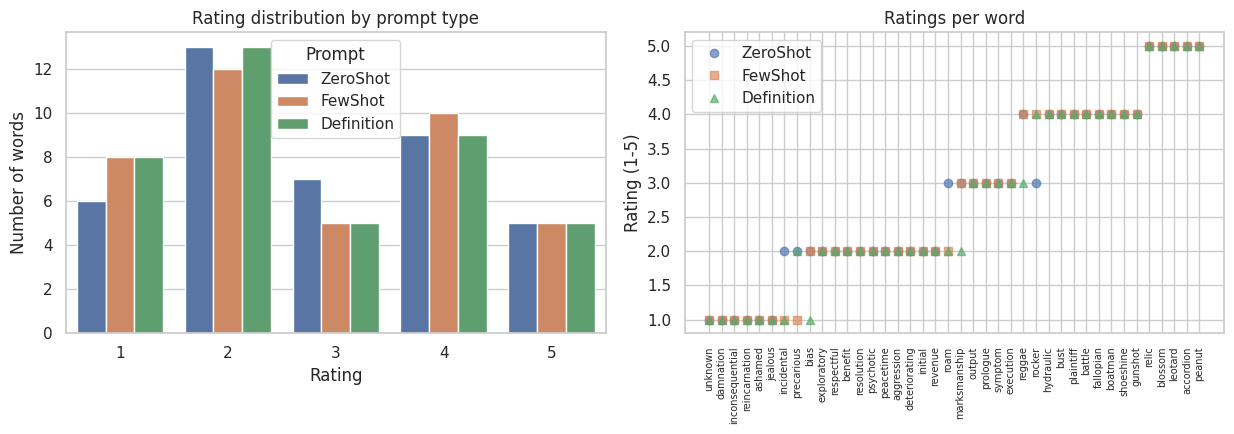

In [ ]:
# (e) Plot
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
long = conc.melt(id_vars="Word", var_name="Prompt", value_name="Rating")
sns.countplot(data=long, x="Rating", hue="Prompt", ax=axes[0])
axes[0].set_title("Rating distribution by prompt type"); axes[0].set_ylabel("Number of words")
o = conc.assign(m=conc[["ZeroShot","FewShot","Definition"]].mean(axis=1)).sort_values("m")
for c, mk in zip(["ZeroShot","FewShot","Definition"], ["o","s","^"]):
    axes[1].plot(o["Word"], o[c], mk, alpha=0.65, label=c)
axes[1].tick_params(axis="x", rotation=90, labelsize=7)
axes[1].set_ylabel("Rating (1-5)"); axes[1].set_title("Ratings per word"); axes[1].legend()
plt.tight_layout(); plt.show()

*Fullest scale:* all span 1–5, but ZeroShot compresses toward the middle (SD = 1.29) while FewShot spreads most (SD = 1.36); only integers in every condition.

*Most human-like:* If comparing with three different techniques the most human like is Few shot, but in general all  three in the same way of not human like resembling.

*Strange outputs:* The strange thing is that in LLM all three prompts produced only integer ratings there were no decimals appeared in any condition.

## Exercise 2 — Stability and order effects


In [ ]:
# Fresh FewShot run, original order
Original = [1,1,1,1,2,1,1,2,2,2,2,2,2,2,2,3,2,3,3,2,2,2,3,2,4,4,4,4,4,3,4,4,4,5,4,4,5,5,5,4]

# Shuffled run: ratings arrived in shuffled order -> map back to canonical word order
shuf_words = ("symptom benefit roam peacetime shoeshine marksmanship initial incidental execution "
              "inconsequential gunshot plaintiff damnation prologue bias hydraulic output aggression "
              "ashamed psychotic peanut fallopian revenue blossom boatman relic leotard unknown "
              "accordion exploratory reggae rocker reincarnation precarious jealous battle "
              "deteriorating bust respectful resolution").split()
shuf_ratings = [3,2,3,2,5,3,1,1,3,1,5,4,1,3,2,3,3,2,1,2,5,3,2,4,4,4,5,1,5,2,3,3,1,1,1,4,2,4,1,2]
smap = dict(zip(shuf_words, shuf_ratings))

ex2 = pd.DataFrame({"Word": WORDS, "Original": Original, "Shuffled": [smap[w] for w in WORDS]})
ex2.head()

,Word,Original,Shuffled
0,unknown,1,1
1,damnation,1,1
2,inconsequential,1,1
3,reincarnation,1,1
4,bias,2,2


In [ ]:
# Consistency, systematic shift, and what drives the differences
r, p = stats.pearsonr(ex2.Original, ex2.Shuffled)
d = ex2.Original - ex2.Shuffled
t, tp = stats.ttest_1samp(d, 0)
print(f"cor(Original, Shuffled) r = {r:.3f} (p = {p:.1e})")
print(f"identical ratings: {(d == 0).sum()}/40")
print(f"mean diff = {d.mean():+.3f}, t(39) = {t:.2f}, p = {tp:.3f}  -> shift NOT significant")

print("\nWords that changed (all by ±1):")
print(ex2.loc[d != 0].assign(diff=d[d != 0]).to_string(index=False))

# Does the difference depend on concreteness level or frequency? (both: no)
mm = ex2.merge(df[["Word","Concreteness","FreqZipf"]], on="Word")
for v in ["Concreteness","FreqZipf"]:
    rr, pp = stats.pearsonr(mm[v], mm.Original - mm.Shuffled)
    print(f"cor({v}, diff) = {rr:+.2f} (p = {pp:.2f})")

cor(Original, Shuffled) r = 0.919 (p = 6.4e-17)
identical ratings: 28/40
mean diff = +0.150, t(39) = 1.78, p = 0.083  -> shift NOT significant

Words that changed (all by ±1):
        Word  Original  Shuffled  diff
     ashamed         2         1     1
     jealous         2         1     1
  respectful         2         1     1
     initial         2         1     1
marksmanship         2         3    -1
      reggae         4         3     1
   fallopian         4         3     1
   hydraulic         4         3     1
   shoeshine         4         5    -1
     blossom         5         4     1
      rocker         4         3     1
     gunshot         4         5    -1
cor(Concreteness, diff) = -0.10 (p = 0.52)
cor(FreqZipf, diff) = +0.27 (p = 0.09)


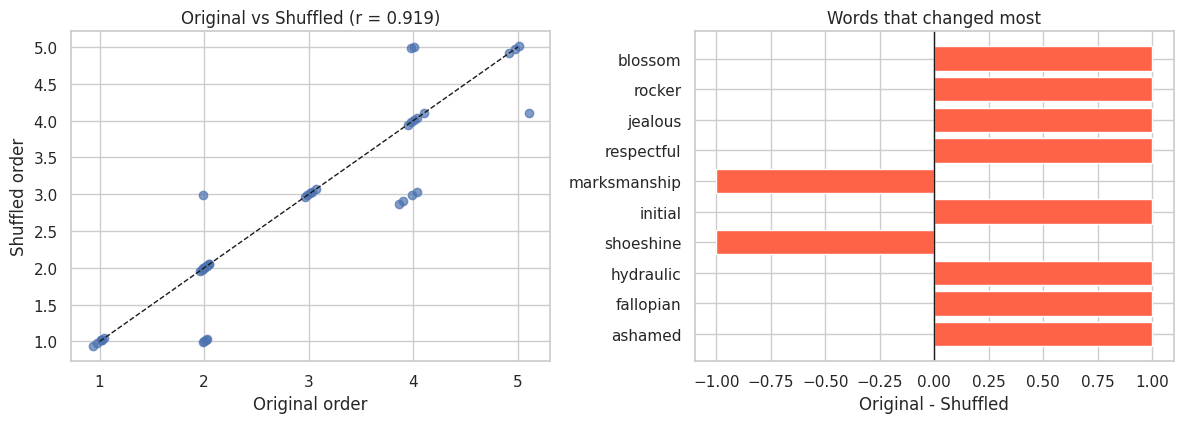

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
jit = np.random.default_rng(1).normal(0, 0.05, 40)
axes[0].scatter(ex2.Original + jit, ex2.Shuffled + jit, alpha=0.7)
axes[0].plot([1,5],[1,5],"k--",lw=1)
axes[0].set_xlabel("Original order"); axes[0].set_ylabel("Shuffled order")
axes[0].set_title(f"Original vs Shuffled (r = {r:.3f})")
top = ex2.assign(diff=d).reindex(d.abs().sort_values(ascending=False).index).head(10)
axes[1].barh(top.Word, top["diff"], color="tomato"); axes[1].axvline(0, color="k", lw=1)
axes[1].set_xlabel("Original - Shuffled"); axes[1].set_title("Words that changed most")
plt.tight_layout(); plt.show()

*Identical?* The ratings are quite identical with the 28/40 words gave the same rating, with correlation between two runs is high r = 0.919. The order adds instability beyond the usual noise, but does not systematically shift the scale.

*Which changed most?* Some words change no more than 1 point. Nine words were rated lower in the shuffled run (ashamed, jealous, respectful, initial, reggae, fallopian, hydraulic, blossom, rocker) and three were rated higher (marksmanship, shoeshine, gunshot). The difference was unrelated to human -rated concreteness and only weakly, non-significantly related to word frequency.


*Why?* Autoregressive list-context (each rating conditions on previous ones, order changes local anchors) + non-deterministic decoding.

## Exercise 3 — Validation against human norms


In [ ]:
conc = conc.merge(df[["Word","Concreteness"]], on="Word").rename(columns={"Concreteness": "Human"})

rows = []
for c in ["ZeroShot","FewShot","Definition"]:
    e = conc[c] - conc.Human
    r_, _ = stats.pearsonr(conc.Human, conc[c])          # agreement
    t, tp = stats.ttest_1samp(e, 0)                       # is the bias reliable?
    re, pe = stats.pearsonr(conc.Human, e)                # does error depend on level?
    slope, ic = np.polyfit(conc.Human, conc[c], 1)        # calibration
    rows.append([c, round(r_,3), round(e.mean(),3), round(tp,4), round(e.abs().mean(),3),
                 round(np.sqrt((e**2).mean()),3), round(re,3), round(pe,3), round(slope,3), round(ic,3)])
pd.DataFrame(rows, columns=["Prompt","r_Human","bias","t-test p","MAE","RMSE",
                            "cor(H,err)","p","lm slope","lm intercept"])

,Prompt,r_Human,bias,t-test p,MAE,RMSE,"cor(H,err)",p,lm slope,lm intercept
0,ZeroShot,0.893,-0.221,2.140e-02,0.499,0.618,0.107,0.510,1.057,-0.398
1,FewShot,0.919,-0.271,4.000e-03,0.514,0.617,0.286,0.073,1.147,-0.724
2,Definition,0.918,-0.322,8.000e-04,0.533,0.639,0.270,0.092,1.138,-0.747


In [ ]:
# Biggest differences for the best measure (FewShot)
e = conc.FewShot - conc.Human
conc.assign(err=e.round(2)).reindex(e.abs().sort_values(ascending=False).index)[
    ["Word","Human","FewShot","err"]].head(8)

,Word,Human,FewShot,err
23,deteriorating,3.38,2,-1.38
9,jealous,2.17,1,-1.17
20,revenue,3.11,2,-1.11
19,initial,3.03,2,-1.03
29,execution,3.93,3,-0.93
31,relic,4.07,5,0.93
39,gunshot,4.93,4,-0.93
17,roam,2.85,2,-0.85


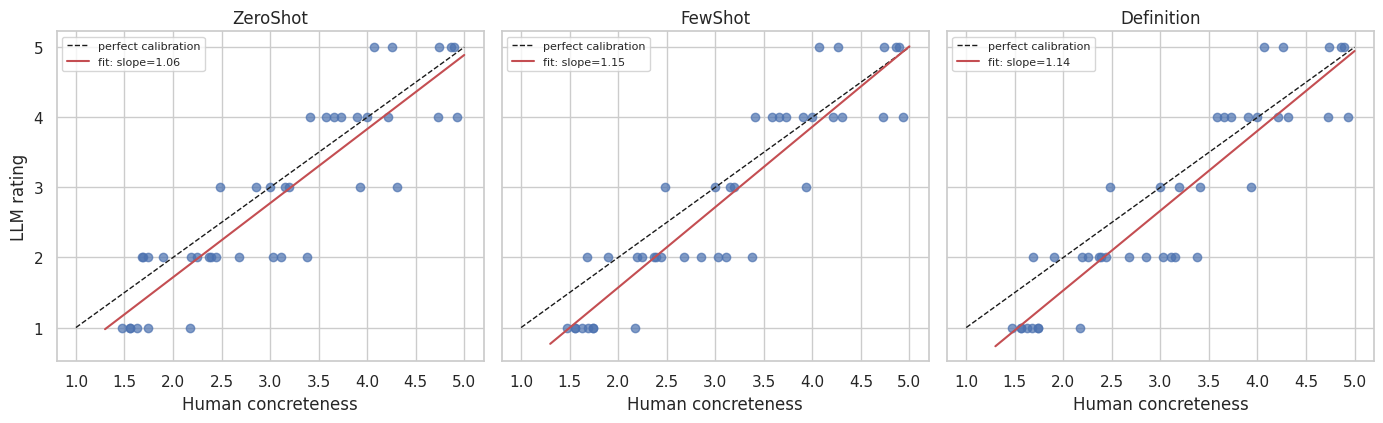

In [ ]:
# Calibration plot: LLM vs Human with identity line and fitted line
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
for ax, c in zip(axes, ["ZeroShot","FewShot","Definition"]):
    ax.scatter(conc.Human, conc[c], alpha=0.7)
    ax.plot([1,5],[1,5],"k--",lw=1,label="perfect calibration")
    slope, ic = np.polyfit(conc.Human, conc[c], 1)
    xs = np.linspace(1.3, 5, 50); ax.plot(xs, slope*xs+ic, "r-", lw=1.5, label=f"fit: slope={slope:.2f}")
    ax.set_title(c); ax.set_xlabel("Human concreteness"); ax.legend(fontsize=8)
axes[0].set_ylabel("LLM rating")
plt.tight_layout(); plt.show()

**Answers (Ex3).** *Closest to human norms:* All three measures are highly correlated with the human norms, with Few shot showing the most resemblance. Worth to notice, the ranking is not the same across metrics: Zeroshot has the smallest average error (MAE = 0.50) despite the weakest correlation, while Fewshot and Definition were tracking human ordering better, they underestimate concreteness more strongly. But in overall, Fewshot gave the best trade off between correlation and error size.


*Biggest differences:* Looking at the best measure (Fewshot) the largest errors are deteriorating (−1.38), jealous (−1.17), revenue (−1.11), initial (−1.03), execution (−0.93) and roam (−0.85)- mid-range words mostly denoting processes, institutional concepts, which humans rate as moderately concrete but the model treats as abstract.


*Random or systematic?* From the systematic, the mean error is negative in all three prompts (ZeroShot −0.22, p = .021; FewShot −0.27, p = .004; Definition −0.32, p < .001). The model consistently underestimates concreteness relative to human raters and, the more information the prompt contains, the stronger the underestimation becomes.
The correlation between human concreteness and the error is positive for all prompts but does not reach significance (ZeroShot r = .11, p = .51; FewShot r = .29, p = .073; Definition r = .27, p = .092).
The model exaggerates the abstract-concrete separation; systematic component of the error is negative bias in overall, while its dependence on the concreteness level remains a non-significant trend.

## Exercise 4 — Predict recognition times


In [ ]:
ex4 = conc.merge(df[["Word","ld_Mean_RT","FreqZipf"]], on="Word", how="left")
print("missing RT:", list(ex4.loc[ex4.ld_Mean_RT.isna(), "Word"]))   # fallopian
sub = ex4.dropna(subset=["ld_Mean_RT"])                               # n = 39

models = {}
for pred in ["Human","ZeroShot","FewShot","Definition"]:
    m = smf.ols(f"ld_Mean_RT ~ {pred}", data=sub).fit()
    models[pred] = m
pd.DataFrame({"Model": list(models),
              "R2": [round(m.rsquared,4) for m in models.values()],
              "b":  [round(m.params[k],2) for k,m in models.items()],
              "p":  [round(m.pvalues[k],3) for k,m in models.items()]})

missing RT: ['fallopian']


,Model,R2,b,p
0,Human,0.018,-13.62,0.418
1,ZeroShot,0.004,-5.41,0.707
2,FewShot,0.009,-7.96,0.559
3,Definition,0.015,-10.10,0.461


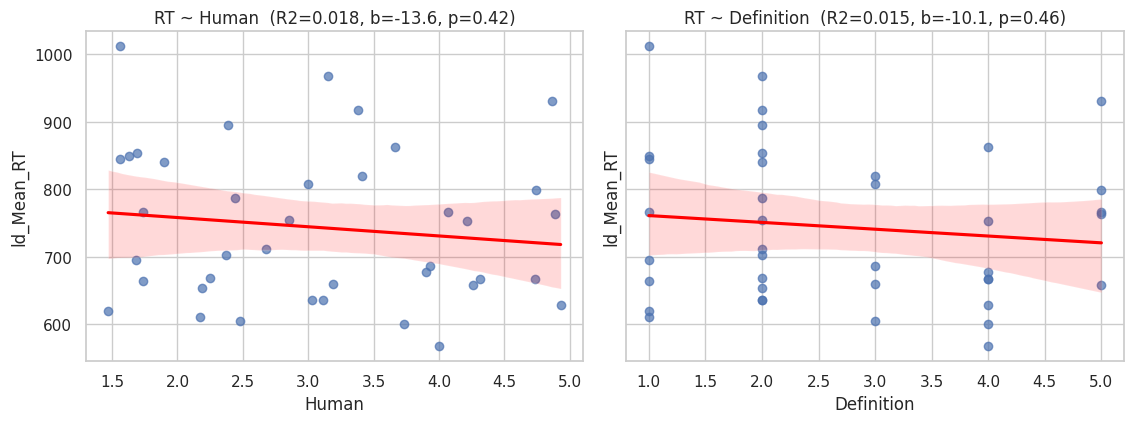

In [ ]:
# Concreteness effect: Human vs best-performing LLM measure (Definition, highest R2 among LLM)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), sharey=True)
for ax, pred in zip(axes, ["Human","Definition"]):
    sns.regplot(data=sub, x=pred, y="ld_Mean_RT", ax=ax, scatter_kws={"alpha":0.7}, line_kws={"color":"red"})
    m = models[pred]
    ax.set_title(f"RT ~ {pred}  (R2={m.rsquared:.3f}, b={m.params[pred]:.1f}, p={m.pvalues[pred]:.2f})")
plt.tight_layout(); plt.show()

In [ ]:
# Add word frequency (task: rerun Human model and best LLM model with FreqZipf)
for pred in ["Human","Definition"]:
    m = smf.ols(f"ld_Mean_RT ~ {pred} + FreqZipf", data=sub).fit()
    print(f"{pred}+Freq: R2={m.rsquared:.3f} | b_{pred}={m.params[pred]:.1f} (p={m.pvalues[pred]:.2f}) "
          f"| b_Freq={m.params['FreqZipf']:.1f} (p={m.pvalues['FreqZipf']:.5f})")
print("FreqZipf alone: R2 =", round(smf.ols("ld_Mean_RT ~ FreqZipf", data=sub).fit().rsquared, 3))

# Are LLM norms contaminated by frequency? Are they good for rare words?
for c in ["Human","ZeroShot","FewShot","Definition"]:
    r_, p_ = stats.pearsonr(sub[c], sub.FreqZipf)
    print(f"cor({c}, FreqZipf) = {r_:+.2f} (p = {p_:.2f})")
low, high = sub[sub.FreqZipf < 3], sub[sub.FreqZipf >= 3]
rl, _ = stats.pearsonr(low.Definition, low.Human); rh, _ = stats.pearsonr(high.Definition, high.Human)
print(f"\nlow-frequency words (Zipf<3, n={len(low)}): r(Def,Human)={rl:.2f}, MAE={(low.Definition-low.Human).abs().mean():.2f}")
print(f"high-frequency words (n={len(high)}):        r(Def,Human)={rh:.2f}, MAE={(high.Definition-high.Human).abs().mean():.2f}")

Human+Freq: R2=0.392 | b_Human=-15.6 (p=0.25) | b_Freq=-97.9 (p=0.00004)
Definition+Freq: R2=0.388 | b_Definition=-11.5 (p=0.30) | b_Freq=-97.8 (p=0.00004)
FreqZipf alone: R2 = 0.369
cor(Human, FreqZipf) = -0.03 (p = 0.85)
cor(ZeroShot, FreqZipf) = -0.08 (p = 0.62)
cor(FewShot, FreqZipf) = -0.07 (p = 0.68)
cor(Definition, FreqZipf) = -0.03 (p = 0.87)

low-frequency words (Zipf<3, n=11): r(Def,Human)=0.96, MAE=0.46
high-frequency words (n=28):        r(Def,Human)=0.90, MAE=0.57


**Answers (Ex4).** *Do concrete words seem easier to process (i.e., shorter reaction times)?*
We can say yes. The slope of the human model id negative b= -13.6, means higher concreteness is associated with shorter reaction times. However in the sample the effect does not reach significance (p = 0.42, R2 = 0.018) so the data hints at the effect without demonstrating it.

*Do LLM ratings support this?*
Yes, in the way the best performing LLM measure, Definition, also shows a negative slope, so the LLM ratings point the same as the human ones. Like the human model, it’s not significant; the LLM measure mirrors the human measure both in direction of the effect and in weakness.

*Would you trust these predictions?*
Neither the human nor the LLM model provides statistically reliable predictions of reaction times, and the concreteness alone explains less than 2% of the variance. In my opinion with this results I wouldn’t trust these predictions.

*Do results change?*
Yes, results change after another run. The results explained variance from R2 = 0.018 to 0.392 in the human model; and from R2 - 0.015 to 0.388 in the Definition model.

*How?*
This change comes from frequency. Characteristic FreqZipf is strong and highly significant predictor in both model, frequent words are recognized faster. While the concreteness predictors remain non-significant even after controlling for frequency.
So even adding frequency doesn’t change a hidden concreteness effect , and it shows that reaction times are driven mostly by word frequency. Additionally, the human model still explains quietly more variance than the LLM model.

*Are LLM-generated norms for low frequency words good?*
Yes, for the 11 low frequency words that we have from our data, the Definition-Human correlation is r = 0.96 with MAE - 0.46 are better than for the higher frequency words, where r = 0.90, MAE = 0.57.


## Answers ex.5

*1. Are LLM-generated norms reliable?*

From the results we can say that is partly reliable, here is why:
- Strong agreement with human norms for both constructs (r ~ 0.89– 0.92) — the ranking of words is trustworthy.
- But the exact values are not: concreteness shows a significant negative bias (−0.22 to −0.32), and valence shows strong polarization (slope ~ 1.45).
- Neither reaches the ~0.96 reliability level of human norms themselves.

*2. Do they work better, worse or the same as human norms?*

As approximations of human evaluation is close, but slightly worse.
As predictors of behavior (RT): no better — Human explained more variance than any LLM measure for concreteness (R² = 0.018 vs ≤ 0.015), and neither predicted anything for valence (R² ≤ .003).
Word frequency dominated all RT models (R² ~ 0.37), for human and LLM norms alike.

*3. Have you observed any prompting effect? Which one?*

While the process I highlighted these effects:
- Anchoring: few-shot examples pushed abstract words toward the scale extremes. FewShot was the best-correlating prompt for both constructs
- Output format: no prompt allowed decimals explicitly, so the model gave only integers in every condition.

*4. Were your norms generally stable?*

The resulted norms were stable. Reordering the words left rating higly correlated  (concreteness r = .919, 28/40 identical; valence r = .983, 33/40). Every change was exactly less or more 1 point; no order-driven shift was significant. Instability concentrated in mid-scale, ambiguous words; valence was clearly more stable than concreteness.

*5. When do you trust them?*

In the situation where **word ordering** matters,  stimulus screening and item selection (clearly concrete vs abstract, positive vs negative). For pilot studies, and for languages/vocabularies without human norms

*6. What are the biggest risks?*

- Treating raw LLM values as calibrated measurements, bias for concreteness, polarization for valence would distort stimulus sets.
- Run-to-run instability: ~10–30% of individual ratings change between runs.
- Implicit details (as an example whether decimals are allowed) shape outputs without warning.


---
# PART B — VALENCE (Exercise 6)

## Exercise 1 (Valence)

In [ ]:
V_ZeroShot   = [4,1,3,6,3,2,5,2,7,2,8,8,7,2,8,5,2,7,5,5,7,6,3,2,8,5,5,3,3,1,2,6,5,8,6,5,5,6,6,1]
V_FewShot    = [4,1,3,6,3,2,5,2,7,2,8,8,7,2,8,5,2,6,5,5,7,6,3,2,8,5,5,3,3,1,2,6,5,8,6,6,5,6,6,1]
V_Definition = [4,1,3,6,3,2,5,2,7,2,8,8,7,2,8,5,2,7,5,5,7,5,3,2,8,5,5,3,3,1,2,6,5,9,6,6,5,6,6,1]

val = pd.DataFrame({"Word": WORDS, "ZeroShot": V_ZeroShot, "FewShot": V_FewShot, "Definition": V_Definition})
val = val.merge(df[["Word","Valence"]], on="Word").rename(columns={"Valence": "Human"})

for c in ["ZeroShot","FewShot","Definition"]:
    print(f"{c:11s} range {val[c].min()}-{val[c].max()} unique={val[c].nunique()} SD={val[c].std():.2f}")
dis = val[(val.ZeroShot != val.FewShot) | (val.FewShot != val.Definition) | (val.ZeroShot != val.Definition)]
print(f"\nPrompts disagree on {len(dis)} of 40 words:"); dis[["Word","ZeroShot","FewShot","Definition"]]

ZeroShot    range 1-8 unique=8 SD=2.23
FewShot     range 1-8 unique=8 SD=2.22
Definition  range 1-9 unique=9 SD=2.27

Prompts disagree on 4 of 40 words:


,Word,ZeroShot,FewShot,Definition
17,roam,7,6,7
21,marksmanship,6,6,5
33,blossom,8,8,9
35,boatman,5,6,6


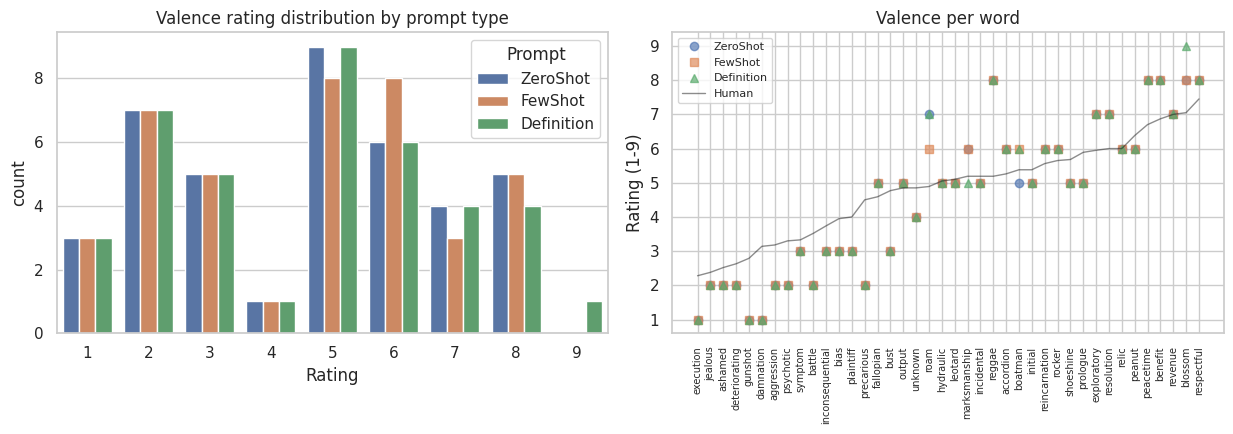

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
long = val.melt(id_vars=["Word","Human"], var_name="Prompt", value_name="Rating")
sns.countplot(data=long, x="Rating", hue="Prompt", ax=axes[0])
axes[0].set_title("Valence rating distribution by prompt type")
o = val.sort_values("Human")
for c, mk in zip(["ZeroShot","FewShot","Definition"], ["o","s","^"]):
    axes[1].plot(o.Word, o[c], mk, alpha=0.65, label=c)
axes[1].plot(o.Word, o.Human, "k-", lw=1, alpha=0.5, label="Human")
axes[1].tick_params(axis="x", rotation=90, labelsize=7)
axes[1].set_ylabel("Rating (1-9)"); axes[1].set_title("Valence per word"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Answers (Ex1, valence).** *Fullest scale:* all conditions span nearly all of 1–9 (Definition reaches 9 with *blossom*), SD ≈ 2.2 — the model actually uses a **wider** range than humans (2.28–7.45): first hint of polarization.

*Most human-like:* FewShot by a small margin; the three conditions disagreed on only 4 words, so prompting mattered even less than for concreteness.

*Strange outputs:* strong polarization of mild words (reggae → 8 vs human 5.19; precarious → 2 vs 4.50); integers only, again.

## Exercise 2 (Valence) — stability

In [ ]:
V_Original = [4,1,3,6,3,2,5,2,7,2,8,8,7,2,8,5,2,7,5,5,7,6,3,2,8,5,5,4,3,1,2,6,5,9,6,5,5,6,6,1]
v_shuf_ratings = [3,8,6,8,5,5,5,5,1,3,1,4,1,5,3,5,6,2,2,2,6,5,7,8,5,6,5,4,6,7,7,6,6,2,2,2,2,3,8,7]
vmap = dict(zip(shuf_words, v_shuf_ratings))
vex2 = pd.DataFrame({"Word": WORDS, "Original": V_Original, "Shuffled": [vmap[w] for w in WORDS]})

r, p = stats.pearsonr(vex2.Original, vex2.Shuffled)
d = vex2.Original - vex2.Shuffled
t, tp = stats.ttest_1samp(d, 0)
print(f"cor = {r:.3f}; identical {(d==0).sum()}/40; mean diff {d.mean():+.2f} (t(39)={t:.2f}, p={tp:.2f})")
print(vex2.loc[d != 0].assign(diff=d[d != 0]).to_string(index=False))
mm = vex2.merge(df[["Word","Valence","FreqZipf"]], on="Word")
for v_ in ["Valence","FreqZipf"]:
    rr, pp = stats.pearsonr(mm[v_], mm.Original - mm.Shuffled)
    print(f"cor({v_}, diff) = {rr:+.2f} (p = {pp:.2f})")

cor = 0.983; identical 33/40; mean diff +0.07 (t(39)=1.14, p=0.26)
        Word  Original  Shuffled  diff
      output         5         6    -1
        roam         7         6     1
marksmanship         6         5     1
      reggae         8         7     1
        bust         4         3     1
   plaintiff         3         4    -1
     blossom         9         8     1
cor(Valence, diff) = +0.16 (p = 0.31)
cor(FreqZipf, diff) = +0.07 (p = 0.68)


**Answers (Ex2, valence).** *Identical?* Nearly: 33/40 identical, r = .983, mean diff +0.08 n.s. (p = .26) — clearly **more stable** than concreteness.

*Changed most:* 7 mid-valence words, all ±1 (roam, marksmanship, reggae, bust, blossom; output, plaintiff); strongly valenced words never moved; unrelated to valence level or frequency.

*Why:* same list-context + decoding noise, weaker here — plausibly because most words have one dominant emotional reading, while concreteness depends on which sense of a polysemous word is considered.

## Exercise 3 (Valence) — validation

In [ ]:
rows = []
for c in ["ZeroShot","FewShot","Definition"]:
    e = val[c] - val.Human
    r_, _ = stats.pearsonr(val.Human, val[c])
    t, tp = stats.ttest_1samp(e, 0)
    re, pe = stats.pearsonr(val.Human, e)
    slope, ic = np.polyfit(val.Human, val[c], 1)
    rows.append([c, round(r_,3), round(e.mean(),2), round(tp,3), round(e.abs().mean(),2),
                 round(np.sqrt((e**2).mean()),2), round(re,3), round(pe,4), round(slope,2), round(ic,2)])
display(pd.DataFrame(rows, columns=["Prompt","r_Human","bias","t p","MAE","RMSE","cor(H,err)","p","slope","intercept"]))

e = val.FewShot - val.Human
val.assign(err=e.round(2)).reindex(e.abs().sort_values(ascending=False).index)[
    ["Word","Human","FewShot","err"]].head(8)

,Prompt,r_Human,bias,t p,MAE,RMSE,"cor(H,err)",p,slope,intercept
0,ZeroShot,0.909,-0.20,0.257,0.89,1.12,0.559,2.000e-04,1.45,-2.36
1,FewShot,0.918,-0.20,0.242,0.87,1.09,0.585,1.000e-04,1.45,-2.39
2,Definition,0.911,-0.18,0.333,0.91,1.15,0.581,1.000e-04,1.48,-2.48


,Word,Human,FewShot,err
24,reggae,5.19,8,2.81
5,precarious,4.50,2,-2.50
1,damnation,3.14,1,-2.14
39,gunshot,2.79,1,-1.79
27,bust,4.77,3,-1.77
30,battle,3.52,2,-1.52
13,psychotic,3.30,2,-1.30
14,peacetime,6.70,8,1.30


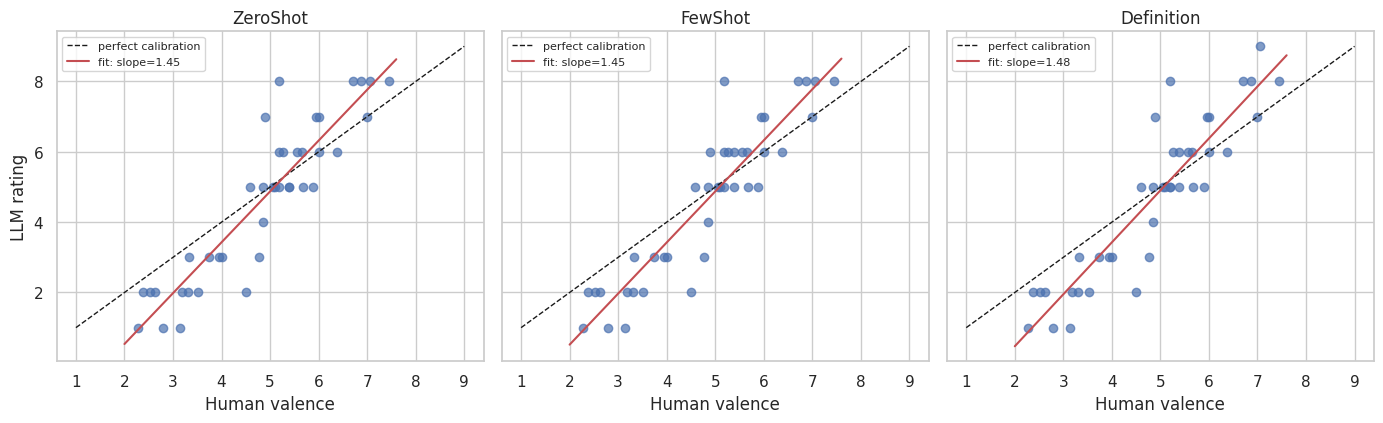

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
for ax, c in zip(axes, ["ZeroShot","FewShot","Definition"]):
    ax.scatter(val.Human, val[c], alpha=0.7)
    ax.plot([1,9],[1,9],"k--",lw=1,label="perfect calibration")
    slope, ic = np.polyfit(val.Human, val[c], 1)
    xs = np.linspace(2, 7.6, 50); ax.plot(xs, slope*xs+ic, "r-", lw=1.5, label=f"fit: slope={slope:.2f}")
    ax.set_title(c); ax.set_xlabel("Human valence"); ax.legend(fontsize=8)
axes[0].set_ylabel("LLM rating")
plt.tight_layout(); plt.show()

**Answers (Ex3, valence).** *Closest:* FewShot again (r = .918, MAE 0.87).

*Biggest differences:* reggae (+2.81), precarious (−2.50), damnation (−2.14), gunshot (−1.79), bust (−1.77) — mildly valenced words pushed to the extremes.

*Random or systematic?* Systematic, but the **mirror image** of concreteness: no significant overall bias (~ −0.20, p > .24), yet a strong, highly significant scaling distortion — cor(Human, error) = .56–.59 (p < .001), slopes ~ 1.45, RMSE >> MAE. The model polarizes emotions: negatives rated more negative, positives more positive than humans rate them.

## Exercise 4 (Valence) — predicting RTs

In [ ]:
vex4 = val.merge(df[["Word","ld_Mean_RT","FreqZipf"]], on="Word", how="left").dropna(subset=["ld_Mean_RT"])
vm = {}
for pred in ["Human","ZeroShot","FewShot","Definition"]:
    m = smf.ols(f"ld_Mean_RT ~ {pred}", data=vex4).fit(); vm[pred] = m
display(pd.DataFrame({"Model": list(vm), "R2": [round(m.rsquared,4) for m in vm.values()],
                      "b": [round(m.params[k],2) for k,m in vm.items()],
                      "p": [round(m.pvalues[k],3) for k,m in vm.items()]}))

# valence effects on RT are often U-shaped -> exploratory quadratic check
mq = smf.ols("ld_Mean_RT ~ H2", data=vex4.assign(H2=(vex4.Human-5)**2)).fit()
print(f"U-shape check RT ~ (Human-5)^2: R2={mq.rsquared:.3f}, p={mq.pvalues['H2']:.2f}  -> also n.s.")

# frequency models (Human and best LLM = ZeroShot)
for pred in ["Human","ZeroShot"]:
    m = smf.ols(f"ld_Mean_RT ~ {pred} + FreqZipf", data=vex4).fit()
    print(f"{pred}+Freq: R2={m.rsquared:.3f} | b_{pred}={m.params[pred]:.1f} (p={m.pvalues[pred]:.2f}) "
          f"| b_Freq={m.params['FreqZipf']:.1f} (p={m.pvalues['FreqZipf']:.5f})")

low, high = vex4[vex4.FreqZipf < 3], vex4[vex4.FreqZipf >= 3]
rl, _ = stats.pearsonr(low.ZeroShot, low.Human); rh, _ = stats.pearsonr(high.ZeroShot, high.Human)
print(f"low-frequency: r={rl:.2f} MAE={(low.ZeroShot-low.Human).abs().mean():.2f} | "
      f"high-frequency: r={rh:.2f} MAE={(high.ZeroShot-high.Human).abs().mean():.2f}")

,Model,R2,b,p
0,Human,3.000e-04,-1.30,0.921
1,ZeroShot,2.900e-03,2.68,0.745
2,FewShot,2.000e-03,2.25,0.786
3,Definition,2.000e-04,0.66,0.935


U-shape check RT ~ (Human-5)^2: R2=0.060, p=0.13  -> also n.s.
Human+Freq: R2=0.369 | b_Human=-2.3 (p=0.83) | b_Freq=-97.3 (p=0.00005)
ZeroShot+Freq: R2=0.371 | b_ZeroShot=2.4 (p=0.72) | b_Freq=-97.1 (p=0.00005)
low-frequency: r=0.92 MAE=0.77 | high-frequency: r=0.91 MAE=0.96


**Answers (Ex4, valence).** *R²:* essentially zero everywhere (≤ .003, all p > .7) — neither human nor LLM valence predicts lexical decision RTs in this sample; numerically ZeroShot (R² = .003) edges out Human (.0003), but the comparison is meaningless at this level. Unlike concreteness, valence effects on RT are known to be weak/non-linear; an exploratory U-shape model was also n.s. (p = .13).

*With FreqZipf:* R² rises to ≈ .37 purely because of frequency (b ≈ −97, p < .0001); valence predictors stay flat.

*Low-frequency words:* again good — r = .92, MAE lower than for frequent words, no correlation with frequency.